In [ ]:
random_state = 42

In [ ]:
import pandas as pd


df = pd.read_csv('data.csv', delimiter=';')

In [ ]:
df

,Unnamed: 0,labels,comment,tokenized,comment_lemmatized,2-grams,3-grams,labels_str,lexical_diversity,main_label
0,1,['NORMAL'],сегодня проезжала рабочей домами снитенко гомо...,"['сегодня', 'проезжала', 'рабочей', 'домами', ...","['сегодня', 'проезжать', 'рабочий', 'дом', 'сн...","['сегодня проезжать', 'проезжать рабочий', 'ра...","['сегодня проезжать рабочий', 'проезжать рабоч...",NORMAL,0.941176,NORMAL
1,2,['NORMAL'],очередной лохотрон придумывать очередной налог...,"['очередной', 'лохотрон', 'придумывать', 'очер...","['очередной', 'лохотрон', 'придумывать', 'очер...","['очередной лохотрон', 'лохотрон придумывать',...","['очередной лохотрон придумывать', 'лохотрон п...",NORMAL,0.972973,NORMAL
2,3,['NORMAL'],ретро дежавю сложно понять чужое сердце лиш ощ...,"['ретро', 'дежавю', 'сложно', 'понять', 'чужое...","['ретро', 'дежавю', 'сложно', 'понять', 'чужое...","['ретро дежавю', 'дежавю сложно', 'сложно поня...","['ретро дежавю сложно', 'дежавю сложно понять'...",NORMAL,1.000000,NORMAL
3,4,['NORMAL'],статус агрогородка получили,"['статус', 'агрогородка', 'получили']","['статус', 'агрогородок', 'получить']","['статус агрогородок', 'агрогородок получить']",['статус агрогородок получить'],NORMAL,1.000000,NORMAL
4,5,['NORMAL'],августа поздно вечером нашли такую потеряшку р...,"['августа', 'поздно', 'вечером', 'нашли', 'так...","['август', 'поздно', 'вечером', 'наслать', 'та...","['август поздно', 'поздно вечером', 'вечером н...","['август поздно вечером', 'поздно вечером насл...",NORMAL,1.000000,NORMAL
...,...,...,...,...,...,...,...,...,...,...
13967,228895,"['OBSCENITY', 'THREAT']",отебу отстераю,"['отебу', 'отстераю']","['отести', 'отстерая']",['отести отстерая'],[],OBSCENITY_THREAT,1.000000,THREAT
13968,233744,"['OBSCENITY', 'THREAT']",трахнуть,['трахнуть'],['трахнуть'],[],[],OBSCENITY_THREAT,1.000000,THREAT
13969,239145,"['OBSCENITY', 'THREAT']",ствола разьебать,"['ствола', 'разьебать']","['ствол', 'разьебать']",['ствол разьебать'],[],OBSCENITY_THREAT,1.000000,THREAT
13970,245139,"['OBSCENITY', 'THREAT']",пожизненно должен сидеть трахать должны каждый...,"['пожизненно', 'должен', 'сидеть', 'трахать', ...","['пожизненно', 'должный', 'сидеть', 'трахать',...","['пожизненно должный', 'должный сидеть', 'сиде...","['пожизненно должный сидеть', 'должный сидеть ...",OBSCENITY_THREAT,0.857143,THREAT


In [ ]:
df['comment_lemmatized'][0]

"['сегодня', 'проезжать', 'рабочий', 'дом', 'снитенко', 'гомолысов', 'магазин', 'пустырь', 'бежать', 'кошка', 'похожий', 'окрас', 'ошибиться', 'необычный', 'окрас', 'броситься', 'глаз']"

Можно заметить, что наш csv распарсился как строка. Можно решить проблему двумя способами.
1) Кодить csv json'ом и декодить соответственно
2) Заюзать eval

Пойдем 2ым способом

In [ ]:
df['comment_lemmatized'] = df['comment_lemmatized'].apply(eval)

In [ ]:
df['comment_lemmatized'][0]

['сегодня',
 'проезжать',
 'рабочий',
 'дом',
 'снитенко',
 'гомолысов',
 'магазин',
 'пустырь',
 'бежать',
 'кошка',
 'похожий',
 'окрас',
 'ошибиться',
 'необычный',
 'окрас',
 'броситься',
 'глаз']

In [ ]:
df['tokenized'] = df['tokenized'].apply(eval)
df['2-grams'] = df['2-grams'].apply(eval)
df['3-grams'] = df['3-grams'].apply(eval)
df['labels'] = df['labels'].apply(eval)

In [ ]:
df['comment_lemmatized_join'] = df['comment_lemmatized'].apply(lambda x: " ".join(x))

In [ ]:
from sklearn.model_selection import train_test_split


df_train, df_test = train_test_split(df, test_size=0.33, random_state=42)

# Lexicon-based

Давайте попробуем составить словарь токсичности per class на train выборке. Можно на самом деле найти готовые модельки со словарями в интернете. Есть, например, VADER для английского. А для русского я нашел модельки https://github.com/sismetanin/sentiment-analysis-in-russian

Попробуем составить свой. Составлять будем по лемматизированным комментам.

В EDA я говорил о том, что будем применять лемматизацию, поэтому давайте составим словари по колонке comment_lemmatized per class. Возьмем, например, 25 слов под каждый класс.

In [ ]:
from nltk.probability import FreqDist
import matplotlib.pyplot as plt

Предлагаю не брать в токсичных словах те, что встречаются в NORMAL словаре, поэтому составим словарь сначало NORMAL комментов.

In [ ]:
def get_toxicity_lexicons(df, lexicon_words_count=25):
    toxicity_lexicons = {'NORMAL': set()}

    # NORMAL
    text_lemmatized = ' '.join([word for comment in df[df['labels_str'] == 'NORMAL']['comment_lemmatized'] for word in comment])
    f_dist = FreqDist(text_lemmatized.split())
    for word in f_dist.most_common(lexicon_words_count):
        toxicity_lexicons['NORMAL'].add(word[0])

    # OTHERS
    for labels in df['labels_str'].value_counts().keys():
        if labels == 'NORMAL':
            continue

        toxicity_lexicons[labels] = set()

        text_lemmatized = ' '.join([word for comment in df[df['labels_str'] == labels]['comment_lemmatized'] for word in comment])
        f_dist = FreqDist(text_lemmatized.split())
        for word_popularity in f_dist.most_common(lexicon_words_count*2):
            word = word_popularity[0]
            if len(toxicity_lexicons[labels]) == lexicon_words_count:
                break
            if word not in toxicity_lexicons['NORMAL']:
                toxicity_lexicons[labels].add(word)
    return toxicity_lexicons

Выведу для проверки глазами в формате set. Если хочется красивый частотный анализ, то он есть в eda

In [ ]:
toxicity_lexicons = get_toxicity_lexicons(df_train)

for labels in df_train['labels_str'].value_counts().keys():
    print(labels, toxicity_lexicons[labels])

NORMAL {'просто', 'всё', 'день', 'такой', 'жизнь', 'год', 'спасибо', 'весь', 'здоровье', 'ребёнок', 'ты', 'какой', 'наш', 'человек', 'бог', 'мой', 'жить', 'ещё', 'дать', 'ваш', 'добрый', 'свой', 'хороший', 'один', 'сам'}
OBSCENITY {'сосать', 'дрочить', 'трахаться', 'жопа', 'сиська', 'член', 'вдуть', 'кто', 'твой', 'рак', 'секс', 'ебать', 'хуй', 'лизать', 'быть', 'трахать', 'рот', 'трахнуть', 'пизда', 'её', 'мочь', 'хотеть', 'очко', 'отсосать', 'попка'}
INSULT_THREAT {'пусть', 'нужно', 'страна', 'этот', 'сволочь', 'яйцо', 'сука', 'посадить', 'тварь', 'убивать', 'стрелять', 'убить', 'повесить', 'быть', 'расстрелять', 'пидор', 'урод', 'место', 'рука', 'мразь', 'который', 'сдохнуть', 'народ', 'кол', 'ублюдок'}
INSULT {'сказать', 'жопа', 'тот', 'страна', 'путин', 'этот', 'сука', 'пидорас', 'тварь', 'хуй', 'путинский', 'блядь', 'пидарас', 'быть', 'пидор', 'урод', 'идти', 'мочь', 'хотеть', 'мразь', 'ёбаный', 'который', 'народ', 'дебил', 'россия'}
THREAT {'сжечь', 'стенка', 'бить', 'нужно', 'с

Стоит отметить, что словари INSULT и THREAT довольно похожи на правду. В THREAT много призывающих глаголов, а в INSULT оскорблений.

Итак, наконец-то переходим к модельке. Напоминаю, что у нас есть пересечение нескольких классов. (INSULT + THREAT == INSULT_THREAT и т.д.)

1) Т.е. на самом деле мы можем составить модельку, где сами будем определять пересечение.
Например, если на THREAT выпало примерно такой же score, что и на INSULT, тогда можно определить, что это INSULT_THREAT. Однако, нам тогда нельзя использовать словари INSULT_THREAT, INSULT_OBSCENITY и т.п.

2) А можем делать модельку еще по словарям пересечений. Т.е. можем включать словари с мультиклассами INSULT_THREAT, INSULT_OBSCENITY и т.п.

Пойдем по второму пути т.к. для нашего датасета он у нас возможен

Наша моделька будет идти по словам комментария и искать их в словарях и добавлять счетчик per class. С самым большим счетчиком будет наш ответ

In [ ]:
def analyze_toxicity(text_lemmatized, lexicons):
    results = {}

    for labels, lexicon in lexicons.items():
        score = 0
        for word in text_lemmatized:
            if word in lexicon:
                score += 1
        results[labels] = score

    return results

In [ ]:
def lexicons_model_predict(toxicity_scores):
    max_toxicity_score = 0
    result = 'NORMAL'
    for toxicity_score in toxicity_scores.items():
        if max_toxicity_score < toxicity_score[1]:
            result = toxicity_score[0]
            max_toxicity_score = toxicity_score[1]
    return result

In [ ]:
df_train['toxicity'] = df_train['comment_lemmatized'].apply(lambda text: analyze_toxicity(text, toxicity_lexicons))
df_train['toxicity']

,toxicity
6427,"{'NORMAL': 1, 'OBSCENITY': 0, 'INSULT_THREAT':..."
12695,"{'NORMAL': 2, 'OBSCENITY': 1, 'INSULT_THREAT':..."
1834,"{'NORMAL': 2, 'OBSCENITY': 0, 'INSULT_THREAT':..."
8847,"{'NORMAL': 0, 'OBSCENITY': 0, 'INSULT_THREAT':..."
8304,"{'NORMAL': 0, 'OBSCENITY': 1, 'INSULT_THREAT':..."
...,...
5191,"{'NORMAL': 0, 'OBSCENITY': 1, 'INSULT_THREAT':..."
13418,"{'NORMAL': 1, 'OBSCENITY': 2, 'INSULT_THREAT':..."
5390,"{'NORMAL': 0, 'OBSCENITY': 0, 'INSULT_THREAT':..."
860,"{'NORMAL': 0, 'OBSCENITY': 0, 'INSULT_THREAT':..."


In [ ]:
df_train['y_lexicons'] = df_train['toxicity'].apply(lexicons_model_predict)
df_train['y_lexicons']

,y_lexicons
6427,INSULT_THREAT
12695,NORMAL
1834,THREAT
8847,THREAT
8304,OBSCENITY
...,...
5191,OBSCENITY
13418,OBSCENITY
5390,NORMAL
860,THREAT


In [ ]:
models_metrics = pd.DataFrame()

In [ ]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score


def metrics(y_true, y_pred):
    accuracy = accuracy_score(y_true, y_pred)
    precision_micro = precision_score(y_true, y_pred, average='micro')
    precision_macro = precision_score(y_true, y_pred, average='macro')
    recall_micro = recall_score(y_true, y_pred, average='micro')
    recall_macro = recall_score(y_true, y_pred, average='macro')
    f1_micro = f1_score(y_true, y_pred, average='micro')
    f1_macro = f1_score(y_true, y_pred, average='macro')
    f1 = f1_score(y_true, y_pred, average='weighted')

    metrics = {"accuracy": accuracy, "precision_micro": precision_micro, "precision_macro": precision_macro, "recall_micro": recall_micro, "recall_macro": recall_macro, "f1_micro": f1_micro, "f1_macro": f1_macro}
    metrics_df = pd.DataFrame([metrics])

    return metrics_df

In [ ]:
def save_metrics(title, models_metrics, metrics_df):
    metrics_df = metrics_df.rename_axis('models_name')
    metrics_df = metrics_df.set_index(pd.Index([title]))
    if models_metrics.empty:
        return metrics_df
    if title in models_metrics.index:
        models_metrics.loc[title] = metrics_df.loc[title].values
        return models_metrics
    return pd.concat([models_metrics, metrics_df])

In [ ]:
y_true = df_train['labels_str']
y_pred = df_train['y_lexicons']

metrics(y_true, y_pred)

,accuracy,precision_micro,precision_macro,recall_micro,recall_macro,f1_micro,f1_macro
0,0.485418,0.485418,0.451387,0.485418,0.386802,0.485418,0.364704


Попробуем увеличить размер словарей.



In [ ]:
toxicity_lexicons = get_toxicity_lexicons(df_train, 100)
df_train['toxicity'] = df_train['comment_lemmatized'].apply(lambda text: analyze_toxicity(text, toxicity_lexicons))
df_train['y_lexicons'] = df_train['toxicity'].apply(lexicons_model_predict)

y_true = df_train['labels_str']
y_pred = df_train['y_lexicons']

metrics(y_true, y_pred)

,accuracy,precision_micro,precision_macro,recall_micro,recall_macro,f1_micro,f1_macro
0,0.496421,0.496421,0.517439,0.496421,0.45294,0.496421,0.416155


Получилось все равно не очень даже на train. Глянем теперь на тест.

In [ ]:
df_test['toxicity'] = df_test['comment_lemmatized'].apply(lambda text: analyze_toxicity(text, toxicity_lexicons))
df_test['y_lexicons'] = df_test['toxicity'].apply(lexicons_model_predict)

y_true = df_test['labels_str']
y_pred = df_test['y_lexicons']

metrics_df = metrics(y_true, y_pred)
print(metrics_df.to_markdown())
models_metrics = save_metrics('linear-based', models_metrics, metrics_df)

|    |   accuracy |   precision_micro |   precision_macro |   recall_micro |   recall_macro |   f1_micro |   f1_macro |
|---:|-----------:|------------------:|------------------:|---------------:|---------------:|-----------:|-----------:|
|  0 |   0.465626 |          0.465626 |          0.414135 |       0.465626 |       0.320928 |   0.465626 |   0.308566 |


Забавно, что чиселки примерно похожие. Я бы сказал, что корреляция какая-то в этом методе даже есть.

Давайте попробуем посмотреть бинарный случай т.е. либо NORMAL, либо что-то другое. Вдруг тут результат будет лучше.

In [ ]:
df_test['toxic'] = df_test['labels_str'].apply(lambda x: 0 if x == 'NORMAL' else 1)
df_test['toxic_lexicons'] = df_test['y_lexicons'].apply(lambda x: 0 if x == 'NORMAL' else 1)

y_true = df_test['toxic']
y_pred = df_test['toxic_lexicons']

metrics(y_true, y_pred)

,accuracy,precision_micro,precision_macro,recall_micro,recall_macro,f1_micro,f1_macro
0,0.665365,0.665365,0.69112,0.665365,0.73027,0.665365,0.656907


Без классификации уже интересней. Давайте теперь попробуем добавить правила.

# Rule-based

Давайте попробуем найти какие-нибудь правила и улучшить функцию analyze_toxicity

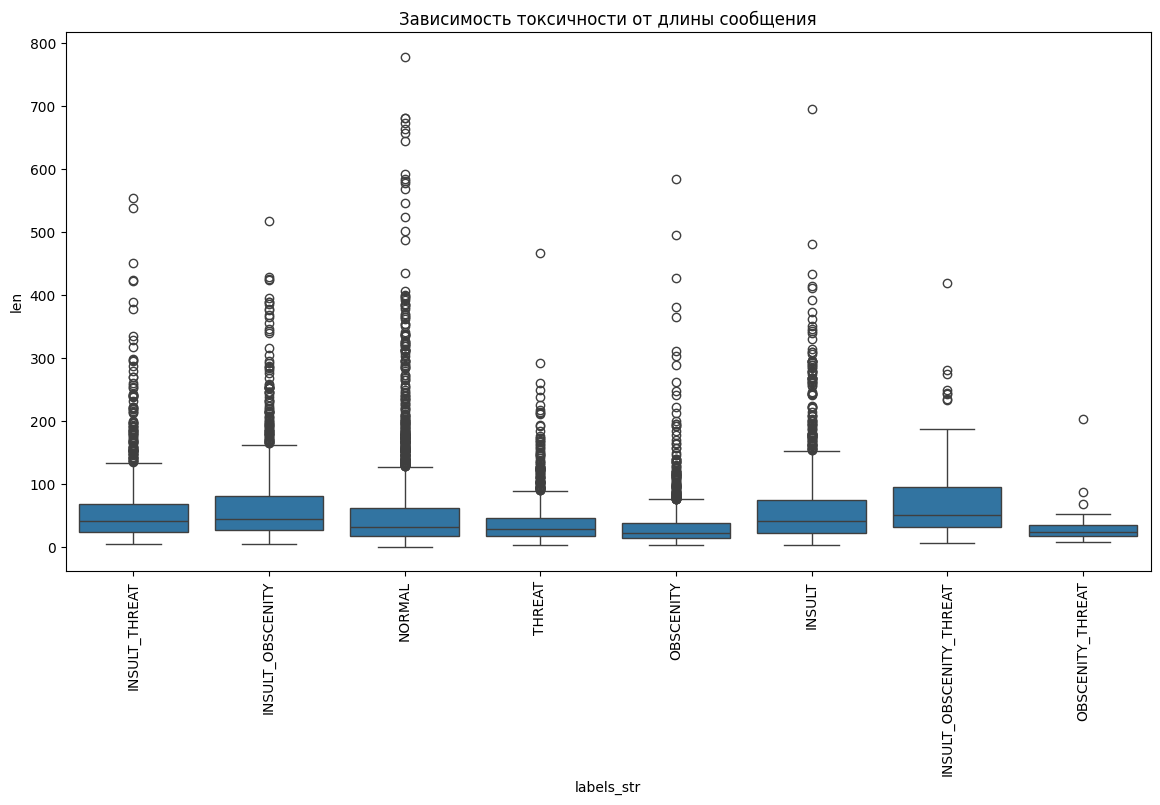

In [ ]:
import seaborn as sns


df_train['len'] = df_train['comment_lemmatized'].apply(lambda x: len(" ".join(x)))

plt.figure(figsize=(14, 7))
sns.boxplot(df_train, x='labels_str', y='len')
plt.title('Зависимость токсичности от длины сообщения')
plt.xticks(rotation=90)
plt.show()

Видно, что THREAT и OBSCENITY в среднем довольно маленькой длины. Давайте попробуем зацепиться за это. Видно еще, что все метки токсичности разом в довольно длинных сообщениях, но это может быть характерно для любых сообщений судя по выбросам и близости верхних квантилей других коробок с усами. Еще добавим оценку сложности текста Flesch-Kincaid.

In [ ]:
import numpy as np


obscenity_median = np.median(df_train['comment_lemmatized_join'].apply(lambda x: len(x)))
obscenity_median

34.0

In [ ]:
!pip install fkscore

fkscore у нас немного не сработает т.к. оказывается у нас появились мусорные комментарии после лемматизации. Сейчас их отловим

In [ ]:
import fkscore


for text in df_train['comment_lemmatized_join']:
    try:
        fkscore.fkscore(text).score['readability']
    except:
        print(text)

г
ч
ю


In [ ]:
anomaly_rows = df_train[(df_train['comment_lemmatized_join'].apply(lambda x: len(x) <= 2)) | (df['comment_lemmatized_join'] == '')]
anomaly_rows

<ipython-input-524-3cc825279801>:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  anomaly_rows = df_train[(df_train['comment_lemmatized_join'].apply(lambda x: len(x) <= 2)) | (df['comment_lemmatized_join'] == '')]


,Unnamed: 0,labels,comment,tokenized,comment_lemmatized,2-grams,3-grams,labels_str,lexical_diversity,main_label,comment_lemmatized_join,toxicity,y_lexicons,len
1362,1686,[NORMAL],г,[г],[г],[],[],NORMAL,1.0,NORMAL,г,"{'NORMAL': 0, 'OBSCENITY': 0, 'INSULT_THREAT':...",NORMAL,1
183,238,[NORMAL],ч,[ч],[ч],[],[],NORMAL,1.0,NORMAL,ч,"{'NORMAL': 0, 'OBSCENITY': 0, 'INSULT_THREAT':...",NORMAL,1
1788,2214,[NORMAL],ю,[ю],[ю],[],[],NORMAL,1.0,NORMAL,ю,"{'NORMAL': 0, 'OBSCENITY': 0, 'INSULT_THREAT':...",NORMAL,1
2294,2811,[NORMAL],лс,[лс],[лс],[],[],NORMAL,1.0,NORMAL,лс,"{'NORMAL': 0, 'OBSCENITY': 0, 'INSULT_THREAT':...",NORMAL,2


In [ ]:
df_train = df_train.drop(anomaly_rows.index)

anomaly_rows = df_test[(df_test['comment_lemmatized_join'].apply(lambda x: len(x) <= 2)) | (df['comment_lemmatized_join'] == '')]
df_test = df_test.drop(anomaly_rows.index)

<ipython-input-525-457fec6877ef>:3: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  anomaly_rows = df_test[(df_test['comment_lemmatized_join'].apply(lambda x: len(x) <= 2)) | (df['comment_lemmatized_join'] == '')]


In [ ]:
df_train['fkscore'] = df_train['comment_lemmatized_join'].apply(lambda comment: fkscore.fkscore(comment).score['readability'])
df_train['fkscore']

,fkscore
6427,108.025
12695,113.100
1834,104.980
8847,120.205
8304,118.175
...,...
5191,116.145
13418,112.085
5390,117.160
860,116.145


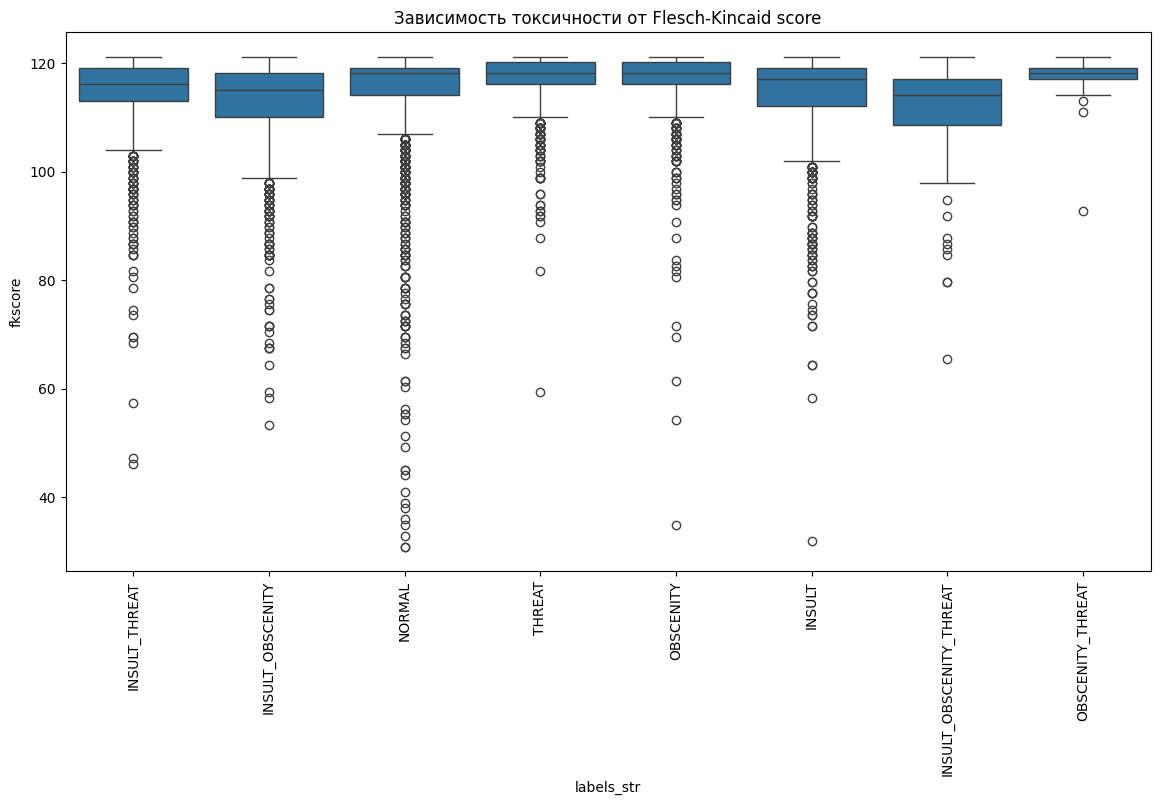

In [ ]:
plt.figure(figsize=(14, 7))
sns.boxplot(df_train, x='labels_str', y='fkscore')
plt.title('Зависимость токсичности от Flesch-Kincaid score')
plt.xticks(rotation=90)
plt.show()

In [ ]:
median = np.median(df_train['fkscore'])
median

117.16

На самом деле очень похоже просто на график с длиной комментария. Думаю, объяснение этому довольно простое. Мы очистили комментарии от знаков препинания в EDA, поэтому если глянуть на формулу fkscore, то можно увидеть, что там используется количество предложений и количество слов, поэтому наша функция по сути зависит только от количества слов, причем линейно. Есть еще слоги. Однако как будто они не очень работают раз график похож на график с длиной сообщения.

Возможно, русские слова не работают в fkscore, поэтому слова считаются как один слог. Если добавим знаки препинания, то по сути мы сделаем просто зависимость предложений от слов.

В добавок у нас большинство комментариев в датасете до 100 символов, что максимум скажется только на предсказании выбросов, где больше 100 символов.

In [ ]:
def analyze_toxicity_with_rules(text_lemmatized, lexicons, len_score):
    results = {}

    for labels, lexicon in lexicons.items():
        score = 0
        for word in text_lemmatized:
            if word in lexicon:
                score += 1
        results[labels] = score

    if len(text_lemmatized) < obscenity_median:
        results['OBSCENITY'] += len_score
        results['THREAT'] += len_score
        results['OBSCENITY_THREAT'] += len_score
    return results

Теперь надо понять какой len_score добавить. По логике маленькие сообщения имеют мало слов, а значит суммарно очков довольно мало. Давайте посмотрим на train. Будем оптимизировать по accuracy.

In [ ]:
y_true = df_train['labels_str']

toxicity_lexicons = get_toxicity_lexicons(df, 100)

best_accuracy = 0
best_len_score = 0
for len_score in range(1, 4):
    df_train['toxicity_ruled'] = df_train['comment_lemmatized'].apply(lambda text: analyze_toxicity_with_rules(text, toxicity_lexicons, len_score))
    df_train['y_ruled'] = df_train['toxicity_ruled'].apply(lexicons_model_predict)

    y_pred = df_train['y_ruled']

    metrics_df = metrics(y_true, y_pred)
    print(metrics_df.to_markdown())
    print('---------------------------------------'*3)

    # Спасибо pandas'у за победу. При True возвращается bool, а при False возвращается pandas.Series с dtype bool. О***но
    # Делаешь .bool(), а он тебе deprecated)))))
    if (metrics_df.at[0, 'accuracy'] > best_accuracy).item():
        best_accuracy = metrics_df['accuracy']
        best_len_score = len_score

|    |   accuracy |   precision_micro |   precision_macro |   recall_micro |   recall_macro |   f1_micro |   f1_macro |
|---:|-----------:|------------------:|------------------:|---------------:|---------------:|-----------:|-----------:|
|  0 |   0.463076 |          0.463076 |          0.489445 |       0.463076 |       0.434874 |   0.463076 |   0.370697 |
---------------------------------------------------------------------------------------------------------------------
|    |   accuracy |   precision_micro |   precision_macro |   recall_micro |   recall_macro |   f1_micro |   f1_macro |
|---:|-----------:|------------------:|------------------:|---------------:|---------------:|-----------:|-----------:|
|  0 |   0.356311 |          0.356311 |          0.502632 |       0.356311 |       0.367349 |   0.356311 |   0.268991 |
---------------------------------------------------------------------------------------------------------------------
|    |   accuracy |   precision_micro |   pr

Мы видим, что accuracy становится хуже, но при этом увеличивается precision macro. Возможно, мы стали больше попадать в OBSCENITY, THREAT, а может стали попадать во что-то другое :)
Но при этом, скорее всего стали меньше попадать в NORMAL сообщения с маленькой длиной.

Тут можно бесконечно экспериментировать с этими score'ами. Например, можно топ 25 слов из словаря сделать условно в 2 балла, а прочие из топ 100 с 1 баллом или там топ 10 дать 3 балла, тогда получится что-то более гибкое, и, возможно, даже при бинарной классификации получится даже что-то стоящее, но для мультиклассовой будет скорее всего грустно.

In [ ]:
df_test['toxicity_ruled'] = df_test['comment_lemmatized'].apply(lambda text: analyze_toxicity_with_rules(text, toxicity_lexicons, best_len_score))
df_test['y_ruled'] = df_test['toxicity_ruled'].apply(lexicons_model_predict)
metrics_df = metrics(y_true, y_pred)
print(metrics_df.to_markdown())
models_metrics = save_metrics('ruled', models_metrics, metrics_df)

|    |   accuracy |   precision_micro |   precision_macro |   recall_micro |   recall_macro |   f1_micro |   f1_macro |
|---:|-----------:|------------------:|------------------:|---------------:|---------------:|-----------:|-----------:|
|  0 |   0.309501 |          0.309501 |          0.516709 |       0.309501 |       0.333765 |   0.309501 |   0.209221 |


Ну вот на тестовой вообще все грустно. Тут еще обрезанный датасет для быстрых экспериментов. Может получились бы более точные словари и анализ длины сообщений был бы чуть другой.

In [ ]:
models_metrics

,accuracy,precision_micro,precision_macro,recall_micro,recall_macro,f1_micro,f1_macro
linear-based,0.465626,0.465626,0.414135,0.465626,0.320928,0.465626,0.308566
ruled,0.309501,0.309501,0.516709,0.309501,0.333765,0.309501,0.209221


# BoW + LogReg

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.preprocessing import LabelEncoder

In [ ]:
y_train, y_test = df_train['labels_str'], df_test['labels_str']
X_train, X_test = df_train['comment_lemmatized_join'], df_test['comment_lemmatized_join']

In [ ]:
vectorizer = CountVectorizer()
vectorizer.fit(X_train)
X_train, X_test = vectorizer.transform(X_train), vectorizer.transform(X_test)

In [ ]:
le = LabelEncoder()
y_train = le.fit_transform(y_train)
y_test = le.transform(y_test)

In [ ]:
clf = LogisticRegression(class_weight='balanced', random_state=random_state)
clf.fit(X_train, y_train)

LogisticRegression(class_weight='balanced', random_state=42)

In [ ]:
y_pred = clf.predict(X_test)
metrics_df = metrics(y_test, y_pred)
print(metrics_df.to_markdown())
models_metrics = save_metrics('BoW + LogReg', models_metrics, metrics_df)

|    |   accuracy |   precision_micro |   precision_macro |   recall_micro |   recall_macro |   f1_micro |   f1_macro |
|---:|-----------:|------------------:|------------------:|---------------:|---------------:|-----------:|-----------:|
|  0 |   0.702451 |          0.702451 |          0.554608 |       0.702451 |       0.548564 |   0.702451 |   0.546056 |


In [ ]:
models_metrics

,accuracy,precision_micro,precision_macro,recall_micro,recall_macro,f1_micro,f1_macro
linear-based,0.465626,0.465626,0.414135,0.465626,0.320928,0.465626,0.308566
ruled,0.309501,0.309501,0.516709,0.309501,0.333765,0.309501,0.209221
BoW + LogReg,0.702451,0.702451,0.554608,0.702451,0.548564,0.702451,0.546056


# BoW + SVM

In [ ]:
from sklearn import svm


clf = svm.SVC(class_weight='balanced', random_state=random_state)
clf.fit(X_train, y_train)

SVC(class_weight='balanced', random_state=42)

In [ ]:
y_pred = clf.predict(X_test)
metrics_df = metrics(y_test, y_pred)
models_metrics = save_metrics('BoW + SVM', models_metrics, metrics_df)
metrics_df

,accuracy,precision_micro,precision_macro,recall_micro,recall_macro,f1_micro,f1_macro
0,0.654088,0.654088,0.532134,0.654088,0.493142,0.654088,0.505004


# BoW + Boosting

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

In [ ]:
clf = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=random_state)
clf.fit(X_train, y_train)

GradientBoostingClassifier(random_state=42)

In [ ]:
y_pred = clf.predict(X_test)
metrics_df = metrics(y_test, y_pred)
models_metrics = save_metrics('BoW + Boosting', models_metrics, metrics_df)
metrics_df

,accuracy,precision_micro,precision_macro,recall_micro,recall_macro,f1_micro,f1_macro
0,0.605725,0.605725,0.494672,0.605725,0.422008,0.605725,0.436035


# TF-IDF + LogReg

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [ ]:
X_train, X_test = df_train['comment_lemmatized_join'], df_test['comment_lemmatized_join']

In [ ]:
vectorizer = TfidfVectorizer()
vectorizer.fit(X_train)
X_train, X_test = vectorizer.transform(X_train), vectorizer.transform(X_test)

clf = LogisticRegression(class_weight='balanced', random_state=random_state)
clf.fit(X_train, y_train)

LogisticRegression(class_weight='balanced', random_state=42)

In [ ]:
y_pred = clf.predict(X_test)
metrics_df = metrics(y_test, y_pred)
models_metrics = save_metrics('TF-IDF + LogReg', models_metrics, metrics_df)
metrics_df

,accuracy,precision_micro,precision_macro,recall_micro,recall_macro,f1_micro,f1_macro
0,0.681197,0.681197,0.546163,0.681197,0.554369,0.681197,0.543272


# TF-IDF + SVM

In [ ]:
clf = svm.SVC(class_weight='balanced', random_state=random_state)
clf.fit(X_train, y_train)

SVC(class_weight='balanced', random_state=42)

In [ ]:
y_pred = clf.predict(X_test)
metrics_df = metrics(y_test, y_pred)
models_metrics = save_metrics('TF-IDF + SVM', models_metrics, metrics_df)
metrics_df

,accuracy,precision_micro,precision_macro,recall_micro,recall_macro,f1_micro,f1_macro
0,0.680113,0.680113,0.567453,0.680113,0.501317,0.680113,0.519865


# TF-IDF + Boosting

In [ ]:
clf = GradientBoostingClassifier(n_estimators=100, learning_rate=1.0, max_depth=1, random_state=random_state)
clf.fit(X_train, y_train)

GradientBoostingClassifier(learning_rate=1.0, max_depth=1, random_state=42)

In [ ]:
y_pred = clf.predict(X_test)
metrics_df = metrics(y_test, y_pred)
models_metrics = save_metrics('TF-IDF + Boosting', models_metrics, metrics_df)
metrics_df

/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


,accuracy,precision_micro,precision_macro,recall_micro,recall_macro,f1_micro,f1_macro
0,0.506615,0.506615,0.396883,0.506615,0.319161,0.506615,0.315329


# N-Grams + Naive Byas

In [ ]:
from sklearn.naive_bayes import MultinomialNB

In [ ]:
X_train, X_test = df_train['comment_lemmatized_join'], df_test['comment_lemmatized_join']
vectorizer = CountVectorizer(ngram_range=(1, 3))
vectorizer.fit(X_train)
X_train, X_test = vectorizer.transform(X_train), vectorizer.transform(X_test)

In [ ]:
clf = MultinomialNB()
clf.fit(X_train, y_train)

MultinomialNB()

In [ ]:
y_pred = clf.predict(X_test)
metrics_df = metrics(y_test, y_pred)
models_metrics = save_metrics('N-Grams + Naive Byas', models_metrics, metrics_df)
metrics_df

# Word2Vec + LogReg

In [ ]:
from gensim.models import Word2Vec

In [ ]:
vector_size = 100

model = Word2Vec(df['comment_lemmatized'].tolist(), vector_size=vector_size, window=5, min_count=5, workers=4)

In [ ]:
def vectorize(model, words, vector_size=300):
    embeddings = [model[word] for word in words if word in model]
    if len(embeddings) == 0:
        return np.zeros(vector_size)
    return np.mean(embeddings, axis=0)

In [ ]:
X_train = np.array([vectorize(model.wv, comment, vector_size) for comment in df_train['comment_lemmatized']])
X_test = np.array([vectorize(model.wv, comment, vector_size) for comment in df_test['comment_lemmatized']])

In [ ]:
clf = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=random_state)
clf.fit(X_train, y_train)

In [ ]:
y_pred = clf.predict(X_test)
metrics_df = metrics(y_test, y_pred)
models_metrics = save_metrics('Word2Vec + LogReg', models_metrics, metrics_df)
metrics_df

Кажется, с Word2Vec пошло что-то не так :(

# Word2Vec + KNN

In [563]:
from sklearn.neighbors import KNeighborsClassifier

In [564]:
clf = KNeighborsClassifier(n_neighbors=3)
clf.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3)

In [565]:
y_pred = clf.predict(X_test)
metrics_df = metrics(y_test, y_pred)
models_metrics = save_metrics('Word2Vec + KNN', models_metrics, metrics_df)
metrics_df

/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


,accuracy,precision_micro,precision_macro,recall_micro,recall_macro,f1_micro,f1_macro
0,0.364129,0.364129,0.331589,0.364129,0.281861,0.364129,0.277848


# Word2Vec + SVM

In [ ]:
clf = svm.SVC(class_weight='balanced')
clf.fit(X_train, y_train)

SVC(class_weight='balanced')

In [ ]:
y_pred = clf.predict(X_test)
metrics_df = metrics(y_test, y_pred)
models_metrics = save_metrics('Word2Vec + SVM', models_metrics, metrics_df)
metrics_df

/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


,accuracy,precision_micro,precision_macro,recall_micro,recall_macro,f1_micro,f1_macro
0,0.146606,0.146606,0.267767,0.146606,0.176985,0.146606,0.095139


# Word2Vec + Boosting

In [ ]:
clf = GradientBoostingClassifier(n_estimators=100, learning_rate=1.0, max_depth=1, random_state=random_state)
clf.fit(X_train, y_train)

GradientBoostingClassifier(learning_rate=1.0, max_depth=1, random_state=42)

In [ ]:
y_pred = clf.predict(X_test)
metrics_df = metrics(y_test, y_pred)
models_metrics = save_metrics('Word2Vec + Boosting', models_metrics, metrics_df)
metrics_df

/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


,accuracy,precision_micro,precision_macro,recall_micro,recall_macro,f1_micro,f1_macro
0,0.437866,0.437866,0.377914,0.437866,0.293814,0.437866,0.293184


# Glove + LogReg

Поюзаем для русских слов https://github.com/natasha/navec

In [ ]:
!pip install navec
!wget https://storage.yandexcloud.net/natasha-navec/packs/navec_hudlit_v1_12B_500K_300d_100q.tar

--2024-12-15 00:40:24--  https://storage.yandexcloud.net/natasha-navec/packs/navec_hudlit_v1_12B_500K_300d_100q.tar
Resolving storage.yandexcloud.net (storage.yandexcloud.net)... 213.180.193.243, 2a02:6b8::1d9
Connecting to storage.yandexcloud.net (storage.yandexcloud.net)|213.180.193.243|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 53012480 (51M) [application/x-tar]
Saving to: ‘navec_hudlit_v1_12B_500K_300d_100q.tar’

navec_hudlit_v1_12B 100%[===================>]  50.56M  19.9MB/s    in 2.5s    

2024-12-15 00:40:27 (19.9 MB/s) - ‘navec_hudlit_v1_12B_500K_300d_100q.tar’ saved [53012480/53012480]



In [ ]:
from navec import Navec

path = 'navec_hudlit_v1_12B_500K_300d_100q.tar'
model = Navec.load(path)

In [ ]:
X_train = np.array([vectorize(model, comment) for comment in df_train['comment_lemmatized']])
X_test = np.array([vectorize(model, comment) for comment in df_test['comment_lemmatized']])

In [ ]:
clf = LogisticRegression(class_weight='balanced', random_state=random_state)
clf.fit(X_train, y_train)

LogisticRegression(class_weight='balanced', random_state=42)

In [ ]:
y_pred = clf.predict(X_test)
metrics_df = metrics(y_test, y_pred)
models_metrics = save_metrics('Glove + LogReg', models_metrics, metrics_df)
metrics_df

,accuracy,precision_micro,precision_macro,recall_micro,recall_macro,f1_micro,f1_macro
0,0.603557,0.603557,0.486081,0.603557,0.508317,0.603557,0.478864


# Glove + KNN

In [ ]:
clf = KNeighborsClassifier(n_neighbors=3)
clf.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3)

In [ ]:
y_pred = clf.predict(X_test)
metrics_df = metrics(y_test, y_pred)
models_metrics = save_metrics('Glove + KNN', models_metrics, metrics_df)
metrics_df

,accuracy,precision_micro,precision_macro,recall_micro,recall_macro,f1_micro,f1_macro
0,0.499458,0.499458,0.427468,0.499458,0.390735,0.499458,0.385946


# Glove + SVM

In [ ]:
clf = svm.SVC(class_weight='balanced')
clf.fit(X_train, y_train)

SVC(class_weight='balanced')

In [ ]:
y_pred = clf.predict(X_test)
metrics_df = metrics(y_test, y_pred)
models_metrics = save_metrics('Glove + SVM', models_metrics, metrics_df)
metrics_df

,accuracy,precision_micro,precision_macro,recall_micro,recall_macro,f1_micro,f1_macro
0,0.685318,0.685318,0.561302,0.685318,0.552448,0.685318,0.552029


# Glove + Boosting

In [ ]:
clf = GradientBoostingClassifier(n_estimators=100, learning_rate=1.0, max_depth=1, random_state=random_state)
clf.fit(X_train, y_train)

GradientBoostingClassifier(learning_rate=1.0, max_depth=1, random_state=42)

In [ ]:
y_pred = clf.predict(X_test)
metrics_df = metrics(y_test, y_pred)
models_metrics = save_metrics('Glove + Boosting', models_metrics, metrics_df)
metrics_df

,accuracy,precision_micro,precision_macro,recall_micro,recall_macro,f1_micro,f1_macro
0,0.602472,0.602472,0.433168,0.602472,0.432757,0.602472,0.432103


# Result

In [ ]:
models_metrics.sort_values(by=['f1_micro'], ascending=False)

,accuracy,precision_micro,precision_macro,recall_micro,recall_macro,f1_micro,f1_macro
BoW + LogReg,0.702451,0.702451,0.554608,0.702451,0.548564,0.702451,0.546056
Glove + SVM,0.685318,0.685318,0.561302,0.685318,0.552448,0.685318,0.552029
TF-IDF + LogReg,0.681197,0.681197,0.546163,0.681197,0.554369,0.681197,0.543272
TF-IDF + SVM,0.680113,0.680113,0.567453,0.680113,0.501317,0.680113,0.519865
N-Grams + Naive Byas,0.664932,0.664932,0.503988,0.664932,0.480376,0.664932,0.472889
BoW + SVM,0.654088,0.654088,0.532134,0.654088,0.493142,0.654088,0.505004
BoW + Boosting,0.605725,0.605725,0.494672,0.605725,0.422008,0.605725,0.436035
Glove + LogReg,0.603557,0.603557,0.486081,0.603557,0.508317,0.603557,0.478864
Glove + Boosting,0.602472,0.602472,0.433168,0.602472,0.432757,0.602472,0.432103
TF-IDF + Boosting,0.506615,0.506615,0.396883,0.506615,0.319161,0.506615,0.315329


Одни из самых лучших вышли BoW + LogReg, TF-IDF + LogReg и Glove + SVM. Неожиданно очень грустно показал себя Word2Vec.